# Remove TEs from proteomes
#### Analysis of TE filtering and TEsorter
### Irene Julca
### -- 20.05.2025 --

In [1]:
import networkx
import pandas as pd
import sys, os
import genome_modules as GM
import glob
import matplotlib.pyplot as plt
import matplotlib.colors
import seaborn as sns
from ete4 import Tree

In [2]:
sns.set(context='notebook', style='ticks', palette='deep', font_scale=1, color_codes=False, rc=None) #font='arial', 

## Check TEs in proteomes

In [3]:
def load_split(inFile):
    genes = []
    for line in open(inFile):
        line = line.strip()
        data = tuple(sorted(line.split(';')))
        genes.append(data)
    return genes

def load_interpro(inFile):
    table = {}
    for line in open(inFile):
        line = line.strip()
        data = line.split('\t')
        table[data[0]] = data[1].split(';')
    return table       

def load_id2pfm(inFile):
    table = {}
    for line in open(inFile):
        line = line.strip()
        if line.startswith('#='):
            data = line.split(' ')
            if data[1] == 'ID':
                name = data[-1]
            elif data[1] == 'AC':
                code = data[-1].split('.')[0]
                if name not in table:
                    table[name] = code
                else:
                    print('Error...', name)
    return table
    
def load_eggnog(inFile, id2pfam):
    goes, pfams = {}, {}
    nopfam = []
    for line in open(inFile):
        line = line.strip()
        data = line.split('\t')
        if line.startswith('#'):
            pass
            # if len(data)>10:
            #     print(data[0],data[9],data[20])
        else:
            gid, go, pfam = data[0], data[9], data[20]
            if go != '-':
                goes[gid] = go.split(',')
            if pfam != '-':
                pfams[gid] = [id2pfam[x] for x in pfam.split(',')]
    return goes, pfams

def load_eggnog_fun(inFile, id2pfam):
    goes, pfams = set(), set()
    nopfam = []
    for line in open(inFile):
        line = line.strip()
        data = line.split('\t')
        if line.startswith('#'):
            pass
        else:
            go, pfam = data[9], data[20]
            if go != '-':
                for fun in go.split(','):
                    goes.add(fun)
            if pfam != '-':
                for fun in [id2pfam[x] for x in pfam.split(',')]:
                    pfams.add(fun)
    return goes, pfams

def splice2annot(genes, table):
    annot = []
    for g in genes:
        if g in table:
            annot.append(g)
    return annot

def loadTaxa(inFile):
    species = {}
    for line in open(inFile):
        line = line.strip()
        data = line.split('\t')
        species[data[0]] = data[1]
    return species

def loadTaxa_reverse(inFile):
    species = {}
    for line in open(inFile):
        line = line.strip()
        data = line.split('\t')
        if data[1] not in species:
            species[data[1]] = set()
        species[data[1]].add(data[0])
    return species
    
def get_colors_sp_idx(xticks):
    species2mnemo = loadTaxa_reverse(taxaFile)
    main_sp = ['Solanum lycopersicum','Solanum lycopersicum var. cerasiforme','Solanum pimpinellifolium']
    main_sp_col = {'Solanum lycopersicum':'#C7253E','Solanum lycopersicum var. cerasiforme':'#FF9F9F','Solanum pimpinellifolium':'#3AB0FF'}
    sp_dict = {x:species2mnemo[x] for x in main_sp}
    colors_sp = {item:main_sp_col[x] for x in main_sp for item in sp_dict[x]}
    colors = []
    for xtick in xticks:
        taxa = xtick.get_text()
        if taxa in colors_sp:
            col = colors_sp[taxa]
        else:
            col = '#262626ff'
        colors.append(col)
    return colors

def load_splice_proteomes(splicePath, protPath):
    splice, proteomes = {}, {}
    if os.path.isdir(splicePath):
        print('Loading splice...')
        for file in glob.glob(f'{splicePath}*'):
            sp = file.split('/')[-1].split('.')[0]
            genes = load_split(file)
            splice[sp] = genes
    if os.path.isdir(protPath):
        print('Loading proteomes...')
        for file in glob.glob(f'{protPath}*.fa'):
            sp = file.split('/')[-1].split('.')[0]
            genes = GM.load_sequences(file)
            proteomes[sp] = genes
    return splice, proteomes
    

In [1]:
pPath = 'project/tomato_domestication/'
dPath = f'{pPath}data/'
rPath = f'{pPath}results/'

goTEfile = f'{dPath}te_datasets/TEs.newGoTerms'
pfTEfile = f'{dPath}te_datasets/TEs.newPfam'

interproGOFile = f'{dPath}go_annotation/interproscan/Tomato_dataset.with_GO.txt'
interproPfamFile = f'{dPath}go_annotation/interproscan/Tomato_dataset.with_Pfam.txt'
pfDBFile = f'{dPath}te_datasets/Pfam-A31.eggnog.hmm.dat'

taxaFile = '../data/'+'names2features.tsv'

### output
pathouT = f'{rPath}tables/functions_noTEs/'
pathouP = f'{rPath}plots/functions_noTEs/'

# annotStatFile1 = f'{pathouT}genes2annotation.tsv'


## Remove viridiplantae no-specific GO 
#### using eggnog results

In [8]:
eggnog_res_old = glob.glob(f'{dPath}go_annotation/old_data/eggnog/*/out.emapper.annotations')
eggnog_res_new = glob.glob(f'{dPath}go_annotation/eggnog/*/*.emapper.annotations')

In [16]:
## load old data:
id2pfam = load_id2pfm(pfDBFile)
goes1, pfams1 = set(), set()
for file in eggnog_res_old:
    go, pfam = load_eggnog_fun(file, id2pfam)
    goes1.update(go)
    pfams1.update(pfam)
print(f'Number of GO: {len(goes1)}')
print(f'Number of Pfam: {len(pfams1)}')

Number of GO: 14553
Number of Pfam: 4453


In [10]:
## load new data (Natasha Viridiplantae)
id2pfam = load_id2pfm(pfDBFile)
goes2, pfams2 = set(), set()
for file in eggnog_res_new:
    go, pfam = load_eggnog_fun(file, id2pfam)
    goes2.update(go)
    pfams2.update(pfam)
print(f'Number of GO: {len(goes2)}')
print(f'Number of Pfam: {len(pfams2)}')

Number of GO: 12147
Number of Pfam: 4288


In [19]:
no_go = set([x for x in goes1 if x not in goes2])
no_pfam = set([x for x in pfams1 if x not in pfams2])
print('Elements to filter from interpro..')
print(f'Number of GO: {len(no_go)}')
print(f'Number of Pfam: {len(no_pfam)}')

Elements to filter from interpro..
Number of GO: 2431
Number of Pfam: 185


In [28]:
### Filter interproscan files
with open(interproGOFile, 'w') as fout:
    for line in open(f'{dPath}go_annotation/old_data/interproscan/Tomato_dataset.with_GO.txt'):
        line = line.strip()
        data = line.split('\t')
        fun = [x for x in data[1].split(';') if x not in no_go]
        if len(fun) >0:
            print(f'{data[0]}\t{';'.join(fun)}', file=fout)

In [29]:
### Filter interproscan files
with open(interproPfamFile, 'w') as fout:
    for line in open(f'{dPath}go_annotation/old_data/interproscan/Tomato_dataset.with_Pfam.txt'):
        line = line.strip()
        data = line.split('\t')
        fun = [x for x in data[1].split(';') if x not in no_pfam]
        if len(fun) >0:
            print(f'{data[0]}\t{';'.join(fun)}', file=fout)

# Load all functions

In [4]:
### Load annotation interpro
inter2go = load_interpro(interproGOFile)
inter2fam = load_interpro(interproPfamFile)
print(f'Number of genes with GO: {len(inter2go)}')
print(f'Number of genes with Pfam: {len(inter2fam)}')

Number of genes with GO: 1444806
Number of genes with Pfam: 1653949


In [13]:
### Load annotation eggnog
files = glob.glob(f'{dPath}go_annotation/eggnog/*/*.emapper.annotations')
id2pfam = load_id2pfm(pfDBFile)
egg2go, egg2fam = {}, {}
for file in files:
    go, pfam = load_eggnog(file, id2pfam)
    egg2go.update(go)
    egg2fam.update(pfam)
print(f'Number of genes with GO: {len(egg2go)}')
print(f'Number of genes with Pfam: {len(egg2fam)}')

Number of genes with GO: 1004202
Number of genes with Pfam: 1854260


In [16]:
with open(f'{dPath}go_annotation/eggnog/Egg2fam.tsv','w') as fout:
    for k,d in egg2fam.items():
        print(f'{k}\t{';'.join(d)}',file=fout)


## TE analysis with the full proteomes

In [6]:
def merge_dicts(dict1, dict2, key_list):
    merged = {}
    for key in key_list:
        values = []
        if key in dict1:
            values.extend(dict1[key])
        if key in dict2:
            values.extend(dict2[key])
        if values:
            merged[key] = list(set(values))  # Ensure uniqueness
    return merged

In [7]:
### Load TEs
gote = pd.read_csv(goTEfile, sep='\t', header=None)
gote = list(gote[0].values)
pfte = pd.read_csv(pfTEfile, sep='\t', header=None)
pfte = list(pfte[0].values)
print(len(gote), len(pfte))

8 130


In [15]:
### Create proteomes and splice files without transposones
outpathProt = f'{dPath}proteome_noTE/'
if os.path.isdir(outpath) == False:
    ! mkdir -p $outpathProt

outpathSpli = f'{dPath}splice_noTE/'
if os.path.isdir(outpath) == False:
    ! mkdir -p $outpathSpli

splice, proteomes = load_splice_proteomes(f'{dPath}splice/', f'{dPath}proteome/')


Loading splice...
Loading proteomes...


In [16]:

for sp, genes in splice.items():
    all_pep = set(proteomes[sp].keys())
    all_go = merge_dicts(inter2go, egg2go, all_pep) ### all genes with go, including isoforms
    all_pf = merge_dicts(inter2fam, egg2fam, all_pep)
    genes_go_te = set([x for x,y in all_go.items() if len(set(y)&set(gote))>0])
    genes_pf_te = set([x for x,y in all_pf.items() if len(set(y)&set(pfte))>0])
    te_genes_iso = genes_go_te.union(genes_pf_te)
    te_genes = [sublist for sublist in genes if any(elem in te_genes_iso for elem in sublist)]
    pepFile = open(f'{outpathProt}{sp}.fa', 'w')
    spliFile = open(f'{outpathSpli}{sp}.splice','w')
    for gene in genes:
        if gene not in te_genes:
            print(';'.join(gene),file=spliFile)
            for g in gene:
                GM.print_sequence(g, proteomes[sp][g], pepFile)
    pepFile.close()
    spliFile.close()
              

In [5]:
### create the TE proteomes - HERE
splice1, proteomes1 = load_splice_proteomes(f'{dPath}splice/', f'{dPath}proteome/')
splice2, proteomes2 = load_splice_proteomes(f'{dPath}splice_noTE/', f'{dPath}proteome_noTE/')


Loading splice...
Loading proteomes...
Loading splice...
Loading proteomes...


In [6]:
outpath = f'{dPath}te_data/'
for sp, genes in splice1.items():
    pepFile = open(f'{outpath}{sp}.te.fa','w')
    spliceFile = open(f'{outpath}{sp}.te.splice','w')
    all_pep = set(proteomes1[sp].keys())
    note_pep = (proteomes2[sp].keys())
    te_pep = [x for x in all_pep if x not in note_pep]
    te_genes = [sublist for sublist in genes if any(elem in te_pep for elem in sublist)]
    print(sp, len(te_genes))
    for gene in te_genes:
        print(';'.join(gene),file=spliceFile)
        for g in gene:
            GM.print_sequence(g, proteomes1[sp][g], pepFile)
    pepFile.close()
    spliceFile.close()

SLM82 3903
TS331 4202
NICBE 9670
CAPC2 3838
TS439 4084
SOLDU 3648
TS185 4076
TS156 4380
TS096 4289
SOLRO 3090
TS009 4461
TS039 4035
SA271 5378
SOLPN 15909
SOLCW 3613
CAPA2 4148
TS629 4260
SOLPE 3730
SA273 4056
LA295 6593
TS623 4024
TS002 4399
NICTA 39106
TS280 4080
TS545 4573
HEINZ 3851
TS166 4025
SOLHA 3839
SOMEL 4199
VITVN 2954
PETAX 3740
TS015 4324
SLSL5 4290
TS421 4633
TS238 3944
TS060 4455
SOTUB 2768
SOLNE 3752
PHYGR 3545
SOLGA 3475
SA275 4642
ARATH 2572
COFEU 5250
TS012 4039
SWEET 3859
TS118 4533
SOLCO 3729
PETIN 4182
LA128 3756
LA209 3949
TS413 4568
TS112 4402
PHAVU 2883
TS265 4414
TS171 4371
TS022 4143
TS222 4100
TS204 4136
TS117 4172
SA102 5528
TS692 4326
TS003 3977
TS080 4037
SOLCH 4028


In [19]:
with open(f'{rPath}tables/genes2annotation_note.tsv', 'w') as fout:
    print('species\tgenes\tno_te', file=fout)
    for file in glob.glob(f'{dPath}splice/*'):
        sp = file.split('/')[-1].split('.')[0]
        tef = f'{outpathSpli}{sp}.splice'
        with open(file,'r') as fp:
            npep = len(fp.readlines())
        with open(tef,'r') as fs:
            nte = len(fs.readlines())
        print(f'{sp}\t{npep}\t{nte}', file=fout)

In [21]:
species2mnemo = loadTaxa_reverse(taxaFile)
main_sp = ['Solanum pimpinellifolium', 'Solanum lycopersicum','Solanum lycopersicum var. cerasiforme']
popu = [item for sublist in [species2mnemo[x] for x in main_sp] for item in sublist]
species_all = sorted(df.index.values)
sp_order = popu+[x for x in species_all if x not in popu]

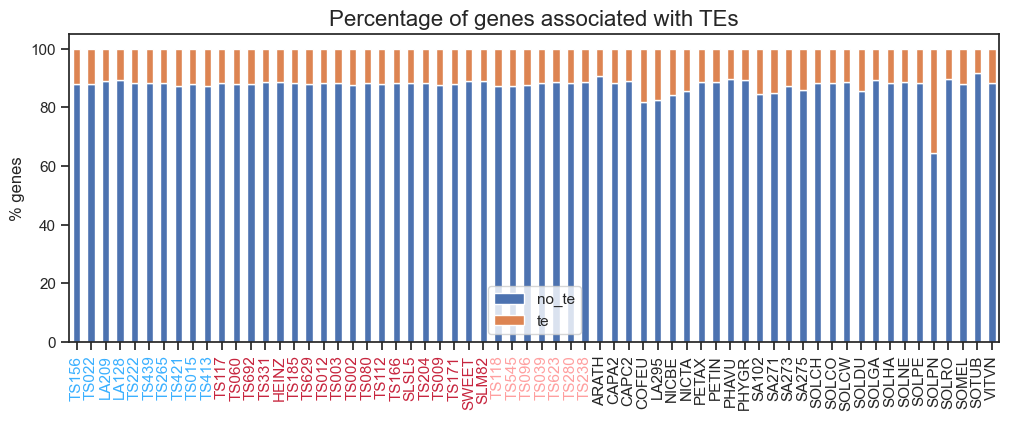

In [77]:
## Plot percentage
df = pd.read_csv(f'{rPath}tables/genes2annotation_note.tsv', sep='\t', index_col=0)
df = df.astype(float)
df.iloc[:, 1:] = df.iloc[:, 1:].div(df.iloc[:, 0], axis=0)*100
df = df[['no_te']]
df['te'] = 100 - df['no_te']
df = df.reindex(sp_order)
ax = df.plot(kind='bar', stacked=True, figsize=(12, 4))
plt.title('Percentage of genes associated with TEs', fontsize=16)
plt.xlabel('')
plt.ylabel('% genes')
plt.xticks(rotation=90)
xticks = ax.get_xticklabels()

colors_sp = get_colors_sp_idx(xticks)
for i, label in enumerate(xticks):
    label.set_color(colors_sp[i % len(xticks)])  # Change colors

plt.savefig(f'{rPath}plots/figure_TE.svg', bbox_inches='tight')
plt.show()

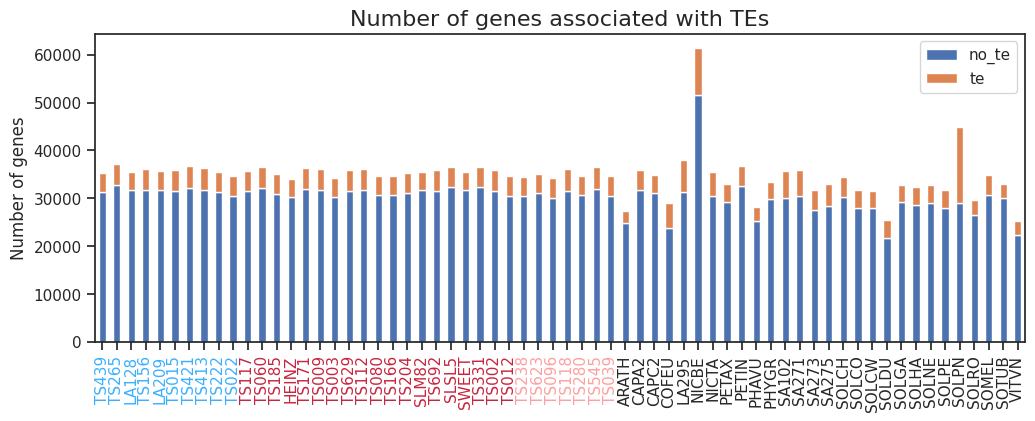

In [34]:
### Plot numbers
df = pd.read_csv(f'{rPath}tables/genes2annotation_note.tsv', sep='\t', index_col=0)
df = df.astype(float)
df['te'] = df['genes'] - df['no_te']
df = df[['no_te', 'te']]
df = df.reindex(sp_order)
ax = df.plot(kind='bar', stacked=True, figsize=(12, 4))
plt.title('Number of genes associated with TEs', fontsize=16)
plt.xlabel('')
plt.ylabel('Number of genes')
plt.xticks(rotation=90)
xticks = ax.get_xticklabels()

colors_sp = get_colors_sp_idx(xticks)
for i, label in enumerate(xticks):
    label.set_color(colors_sp[i % len(xticks)])  # Change colors

plt.savefig(f'{rPath}plots/figure_TE_nums.svg', bbox_inches='tight')
plt.show()

## Functional analysis

In [ ]:
splice, proteomes = load_splice_proteomes(f'{dPath}splice_noTE/', f'{dPath}proteome_noTE/')

In [8]:
with open(annotStatFile1, 'w') as fout:
    print('species\tgenes\tgo_interpro\tpfam_interpro\tgo_eggnog\tpfam_eggnog\tall_go\tall_pfam', file=fout)
    for sp, genes in splice.items():
        intergo = [sublist for sublist in genes if any(elem in inter2go for elem in sublist)]
        interfam = [sublist for sublist in genes if any(elem in inter2fam for elem in sublist)]
        egggo = [sublist for sublist in genes if any(elem in egg2go for elem in sublist)]
        eggfam = [sublist for sublist in genes if any(elem in egg2fam for elem in sublist)]
        all_go = set(intergo+egggo)
        all_fam = set(interfam+eggfam)
        string = f'{sp}\t{len(genes)}\t{len(intergo)}\t{len(interfam)}\t{len(egggo)}\t{len(eggfam)}\t{len(all_go)}\t{len(all_fam)}'
        print(string, file=fout)
    

In [9]:
sns.set(context='notebook', style='ticks', palette='deep', font_scale=1, color_codes=False, rc=None)

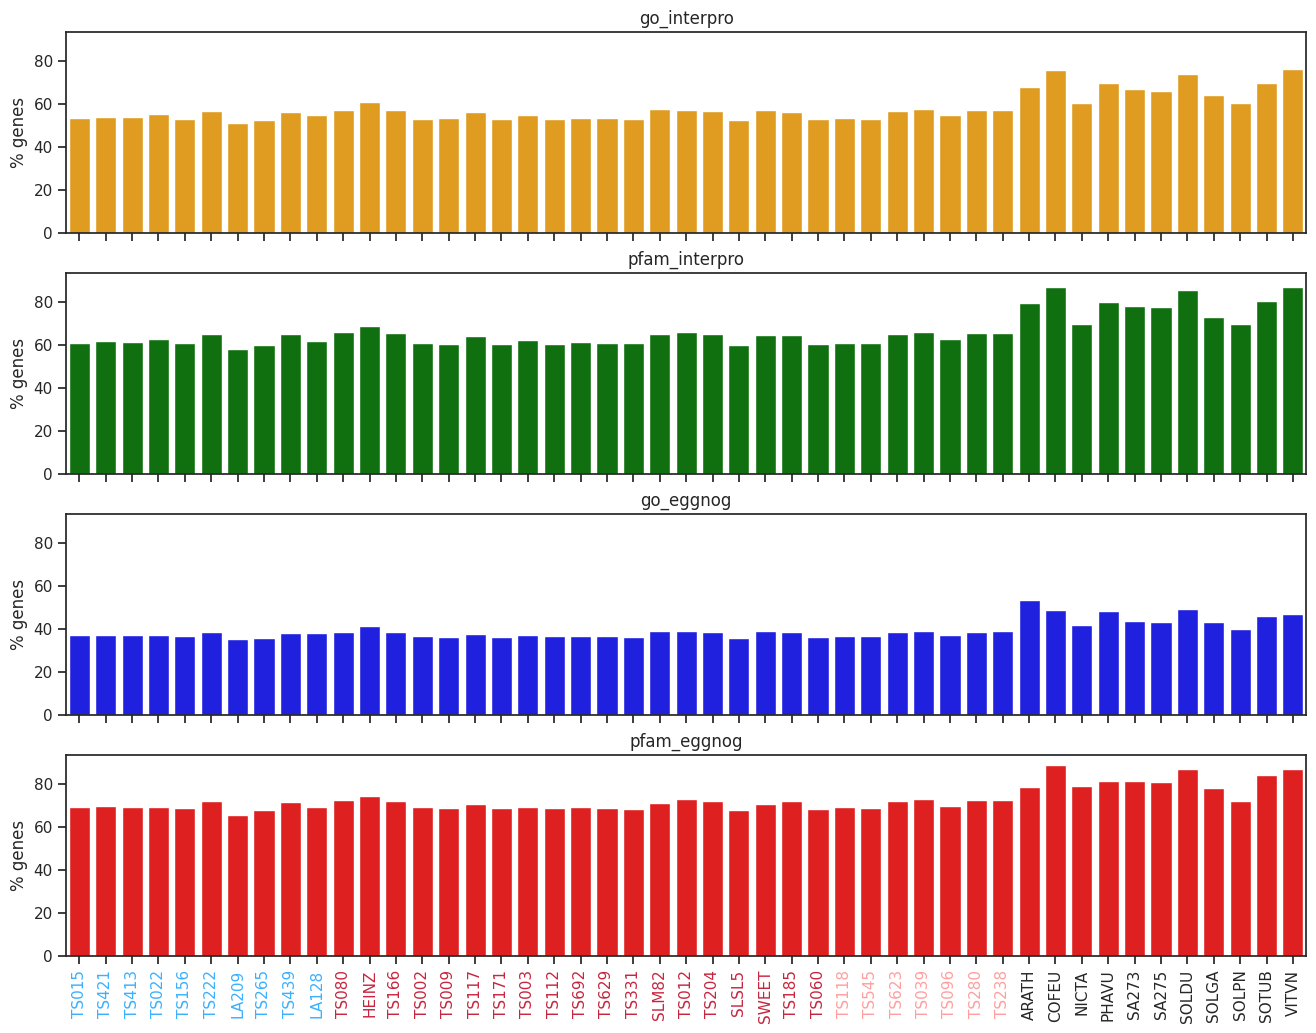

In [14]:
species2mnemo = loadTaxa_reverse(taxaFile)
main_sp = ['Solanum pimpinellifolium', 'Solanum lycopersicum','Solanum lycopersicum var. cerasiforme']
popu = [item for sublist in [species2mnemo[x] for x in main_sp] for item in sublist]

df = pd.read_csv(annotStatFile1, sep='\t', index_col=0)
df = df.astype(float)
df.iloc[:, 1:] = df.iloc[:, 1:].div(df.iloc[:, 0], axis=0)*100
df = df.drop(['genes'], axis=1)
species_all = sorted(df.index.values)
sp_order = popu+[x for x in species_all if x not in popu]
df = df.reindex(sp_order)

annot = df.columns.values[:-2]
colors = ['orange','green','blue','red']
fig, axes = plt.subplots(nrows=len(annot), ncols=1, figsize=(16,3*len(annot)), sharex=True, sharey=True)
axes = axes.flatten()
for i,e in enumerate(annot):
    df2 = df[[e]].copy()
    df2['species'] = df2.index
    sns.barplot(data=df2, x='species', y=e, ax=axes[i], color=colors[i])
    axes[i].set_title(e)
    axes[i].set_ylabel('% genes')
    axes[i].set_xlabel('')

plt.xticks(rotation=90)
xticks = axes[i].get_xticklabels()

colors_sp = get_colors_sp_idx(xticks)
for i, label in enumerate(xticks):
    label.set_color(colors_sp[i % len(xticks)])  # Change colors

plt.savefig(f'{pathouP}figure_fun_interpro_egg.svg', bbox_inches='tight')
plt.show()



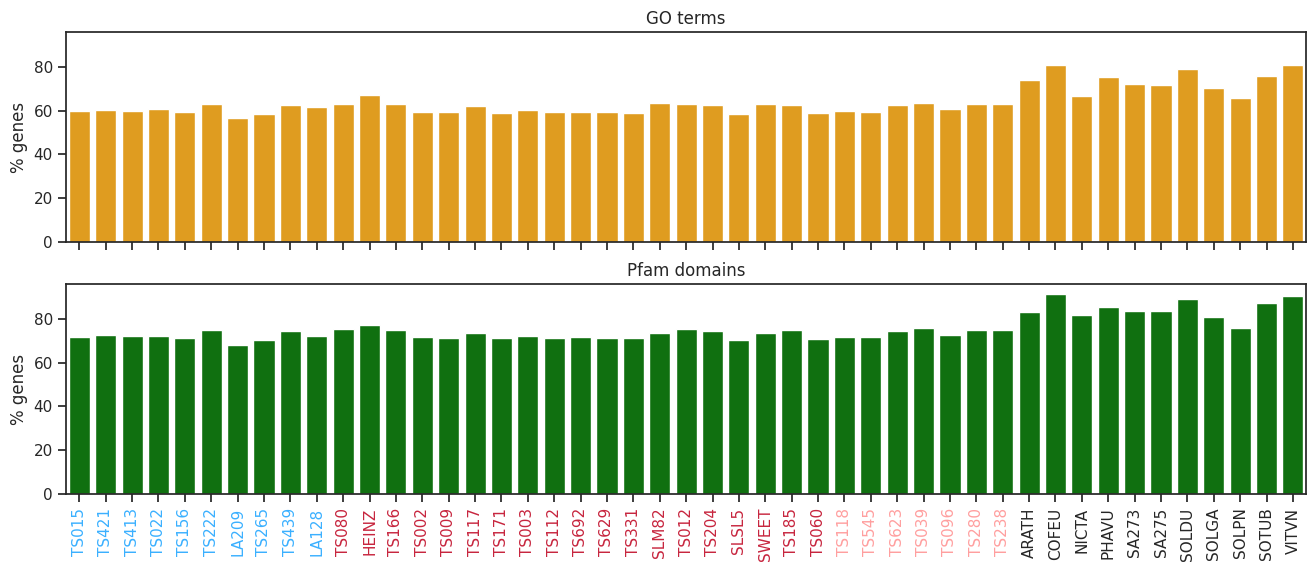

In [15]:
annot = df.columns.values[-2:]
colors = ['orange','green','blue','red']
fig, axes = plt.subplots(nrows=len(annot), ncols=1, figsize=(16,3*len(annot)), sharex=True, sharey=True)
axes = axes.flatten()
for i,e in enumerate(annot):
    df2 = df[[e]].copy()
    df2['species'] = df2.index
    sns.barplot(data=df2, x='species', y=e, ax=axes[i], color=colors[i])
    if e == 'all_go':
        head = 'GO terms'
    else:
        head = 'Pfam domains'
    axes[i].set_title(head)
    axes[i].set_ylabel('% genes')
    axes[i].set_xlabel('')

plt.xticks(rotation=90)
xticks = axes[i].get_xticklabels()

colors_sp = get_colors_sp_idx(xticks)
for i, label in enumerate(xticks):
    label.set_color(colors_sp[i % len(xticks)])  # Change colors
plt.savefig(f'{pathouP}/figure_fun_all.svg', bbox_inches='tight')
plt.show()

### Upadate the lists of GO and pfam associated with TEs

In [103]:
def load_pfm_hmm(inFile):
    table = {}
    for line in open(inFile):
        line = line.strip()
        if line.startswith('#='):
            data = line.split(' ')
            if data[1] == 'ID':
                name = data[-1]
            elif data[1] == 'AC':
                code = data[-1].split('.')[0]
                if code not in table:
                    table[code] = [name]
                else:
                    print('Error...', code)
            elif data[1] == 'DE':
                table[code].append(line.split('  ')[1])
    return table

In [104]:
### Data
pPath = 'project/tomato_domestication/'
dPath = f'{pPath}data/'
protPath = f'{dPath}/proteomes/'
oboGOFile = f'{dPath}te_datasets/go.obo' ### from go ontology web
goTEfile = f'{dPath}/te_datasets/TEs.GoTerms'
newgoTEfile = f'{dPath}/te_datasets/TEs.newGoTerms'

pfDBFileI = f'{dPath}te_datasets/Pfam-A35.interpro.hmm.dat' ## from interproscan, latest
pfDBFileE = f'{dPath}te_datasets/Pfam-A31.eggnog.hmm.dat' ## from interproscan
pfFile = f'{dPath}te_datasets/TEs.pfam.lib'
newpfFile = f'{dPath}te_datasets/TEs.newPfam'

#### GO terms

In [105]:
graph = obonet.read_obo(oboGOFile)

In [106]:
te_terms = ['transposon','transposase','MULE','MuDR','CACTA','Spm','retrotransposon','Ty1','RNA-mediated',
                'DDE_Tnp','DBD_Tnp_Mut','Transposase','Transpos_assoc','MULE','MuDR','FAR1','rve','RVT','RVP',
                'Retrotran_gag','gag_pre-integrs','Asp_protease_2']
te_terms = list(set([w.lower() for w in te_terms if not w.lower() in stop_words]))


In [107]:
go_tes = set()
for code, data in graph.nodes(data=True):
    name = data.get('name')
    tokens = [x.lower() for x in word_tokenize(name)]
    tes = [x for x in te_terms if x in tokens]
    if len(tes)>0:
        go_tes.add(code)
        print(code, name, tes)
print(len(go_tes))

GO:0000943 retrotransposon nucleocapsid ['retrotransposon']
GO:0004803 transposase activity ['transposase']
GO:0042152 RNA-mediated DNA recombination ['rna-mediated']
3


In [108]:
df = pd.read_csv(goTEfile, sep='\t', header=None)
goes = set(list(df[0].values) + list(go_tes))
keys = ['namespace','name','def']

with open(newgoTEfile,'w') as fout:
    for code, data in graph.nodes(data=True): 
        if code in goes:
            info = [data.get(x) for x in keys]
            string = f"{code}\t{'\t'.join(info)}"
            print(string, file=fout)


#### Pfam

In [114]:
pfam_table = load_pfm_hmm(pfDBFileI)
print(len(pfam_table))
pfam_table2 = load_pfm_hmm(pfDBFileE)
pfam_table.update({x:y for x,y in pfam_table2.items() if x not in pfam_table})
print(len(pfam_table2), len(pfam_table))

24424
16712 24529


In [115]:
new_pfam = set()
for pf in pfam_table:
    name = pfam_table[pf][1]
    tokens = [x.lower() for x in word_tokenize(name)]
    tes = [x for x in te_terms if x in tokens]
    if len(tes)>0:
        new_pfam.add(pf)
        print(pf, name, tes)
print(len(new_pfam))

PF07863  Homologues of TraJ from Bacteroides conjugative transposon ['transposon']
PF10683  Hermes transposase DNA-binding domain ['transposase']
PF03108  MuDR family transposase ['mudr', 'transposase']
PF02914  Bacteriophage Mu transposase ['transposase']
PF01609  Transposase DDE domain ['transposase']
PF13586  Transposase DDE domain ['transposase']
PF13612  Transposase DDE domain ['transposase']
PF13701  Transposase DDE domain group 1 ['transposase']
PF13737  Transposase DDE domain ['transposase']
PF13751  Transposase DDE domain ['transposase']
PF13843  Transposase IS4 ['transposase']
PF04693  Archaeal putative transposase ISC1217 ['transposase']
PF03400  IS1 transposase ['transposase']
PF12762  ISXO2-like transposase domain ['transposase']
PF03050  Transposase IS66 family ['transposase']
PF07592  Rhodopirellula transposase DDE domain ['transposase']
PF01610  Transposase ['transposase']
PF01526  Tn3 transposase DDE domain ['transposase']
PF01548  Transposase ['transposase']
PF02281  

In [116]:
### Curated list and general terms to be removed:
remove = ['PF01807', 'PF07530', 'PF09337', 'PF12874', 'PF12009', 'PF04434', 'PF03101']
###
df = pd.read_csv(pfFile, sep='\t', header=None)
print(df.shape)
pfam_all = set(list(df[0].values)+list(new_pfam))
print(len(pfam_all))
pfam_all = set([x for x in pfam_all if x not in remove])
print(len(pfam_all))

(99, 3)
137
130


In [117]:
with open(newpfFile, 'w') as fout:
    for pf in pfam_all:
        string = f'{pf}\t{'\t'.join(pfam_table[pf])}'
        print(string, file=fout)

In [39]:
### Check Natasha comments
inFile = f'{dPath}te_datasets/TEs_NG.newpfam.xlsx'
df = pd.read_excel(inFile)
df.Notes = df.Notes.astype('str')
df = df[df.Notes != 'nan']
# df.to_excel(f'{dPath}te_datasets/NG_pfam_description.xlsx')
df

,Unnamed: 0,Unnamed: 1,Unnamed: 2,Notes
0,PF07282,Cas12f1-like_TNB,"Cas12f1-like, TNB domain",might be too restrictive
5,PF01807,Zn_ribbon_DnaG,CHC2 zinc finger,"seems to general, and I think SSP is a zinc fi..."
23,PF07530,PRE_C2HC,Associated with zinc fingers,Too general?
43,PF00075,RNase_H,RNase H,too general?
56,PF09337,zf-H2C2,H2C2 zinc finger,"Binds to histone promotors, not seeing the rel..."
72,PF12874,zf-met,Zinc-finger of C2H2 type,Too general?
101,PF12009,Telomerase_RBD,Telomerase ribonucleoprotein complex - RNA bi...,"Maybe not TE related, but for telomeres"
123,PF04434,SWIM,SWIM zinc finger,Not convinced on this one based on the descrip...
127,PF03101,FAR1,FAR1 DNA-binding domain,"I think this is related to, but not an actual ..."


In [40]:
remove = df['Unnamed: 0'].values
print(len(remove))
noremove = ['PF07282','PF00075']
remove = [x for x in remove if x not in noremove]
print(len(remove))
print(remove)

9
7
['PF01807', 'PF07530', 'PF09337', 'PF12874', 'PF12009', 'PF04434', 'PF03101']


# Types of TEs - TEsorter analysis

In [160]:
pPath = 'project/tomato_domestication/'
dPath = f'{pPath}data/'
rPath = f'{pPath}results/te_filters/'

teFile = f'{rPath}te_filter_table.tsv'
taxaFile = f'{dPath}names2features.tsv'

### outfiles
ngFile = f'{rPath}genes_note.tsv'
tes_confirmed = f'{rPath}te_confirmed.tsv'

In [187]:
def load_te_type(inFile):
    table = {}
    for line in open(inFile):
        line = line.strip()
        data = line.split('\t')
        table[data[0]] = [data[1], data[2]]
    return table

### All proteome analysis

In [23]:
### Loading all proteomes and splice files
splice, proteomes = load_splice_proteomes(f'{dPath}splice/', f'{dPath}proteome/')

Loading splice...
Loading proteomes...


In [24]:
### loading tes
df = pd.read_csv(teFile, sep='\t')
tes = set(df.prot_id.values)
print(f'Number of TE genes in the dataset: {len(tes)}')

Number of TE genes in the dataset: 481009


In [32]:
### get values and TE files
values = []
outpath = f'{rPath}te_fasta/'
for sp, genes in splice.items():
    te_genes = [sublist for sublist in genes if any(elem in tes for elem in sublist)]
    dades = [sp, len(genes), len(genes)-len(te_genes)]
    values.append(dades)
    pepFile = open(f'{outpath}{sp}.te.fa','w')
    spliceFile = open(f'{outpath}{sp}.te.splice','w')
    for genes in te_genes:
        print(';'.join(genes), file=spliceFile)
        for g in genes:
            GM.print_sequence(g, ''.join(proteomes[sp][g]), pepFile)
    pepFile.close()
    spliceFile.close()

In [33]:
### store the dataframe
df = pd.DataFrame(values, columns=['species','genes','No TE'])
df.to_csv(ngFile, sep='\t', index=False)

In [28]:
### get species order and colors
df = pd.read_csv(taxaFile, sep='\t')
color_dic = df.groupby('color')['sciname'].apply(list).to_dict()
order_colors = ['#C7253E','#FF9F9F','#3AB0FF','#89a02cff','#5fd3bcff','#4d4d4dff']
ordered_sp = [item for key in order_colors if key in color_dic for item in color_dic[key]]
ordered_col = [[x]*len(color_dic[x]) for x in order_colors]
ordered_col = [item for sublist in ordered_col for item in sublist]

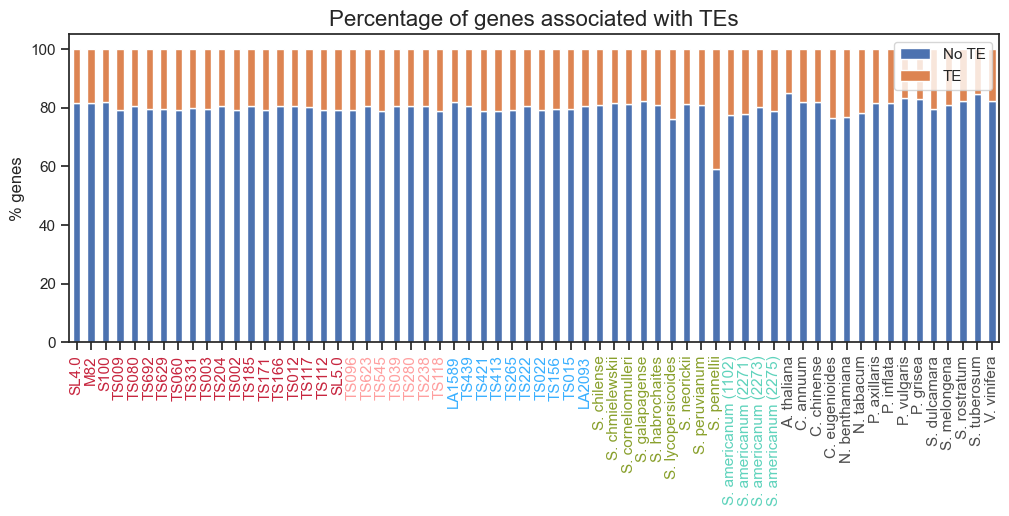

           No TE         TE
count  64.000000  64.000000
mean   79.894741  20.105259
std     3.130986   3.130986
min    59.059268  15.221039
25%    79.188988  18.813605
50%    80.381292  19.618708
75%    81.186395  20.811012
max    84.778961  40.940732


In [31]:
### Plot percentage
nf = pd.read_csv(taxaFile, sep='\t')
id2names = dict(zip(nf.id, nf.sciname))
df = pd.read_csv(ngFile, sep='\t')
df.species = df.species.map(id2names)
df = df.set_index("species", drop=True)
df = df.astype(float)
df.iloc[:, 1:] = df.iloc[:, 1:].div(df.iloc[:, 0], axis=0)*100
df = df[['No TE']]
df['TE'] = 100 - df['No TE']
df = df.reindex(ordered_sp)
ax = df.plot(kind='bar', stacked=True, figsize=(12, 4))
plt.title('Percentage of genes associated with TEs', fontsize=16)
plt.xlabel('')
plt.ylabel('% genes')
plt.xticks(rotation=90)
xticks = ax.get_xticklabels()

for i, label in enumerate(xticks):
    label.set_color(ordered_col[i % len(xticks)])  # Change colors

plt.savefig(f'{rPath}TEs_inproteome.svg', bbox_inches='tight')
plt.show()
print(df.describe())

# Origin of TE-associated genes

In [147]:
import pyham
import ete4
from tqdm import tqdm

In [148]:
orthoxmlFile= f'{rPath}fastoma_results/FastOMA_HOGs.orthoxml'
treeFile = f'{rPath}fastoma_results/species_tree_checked.nwk'
treeFile2 = f'{rPath}fastoma_results/species_tree_checked_relabelled.nwk'

orthoFile = f'{rPath}fastoma_results/FastOMA_HOGs.tsv'
nodeNameFile = f'{rPath}fastoma_results/node2newnames.tsv'

In [149]:
ham_analysis = pyham.Ham(hog_file=orthoxmlFile)

[2026-10-13 16:01:41,979] Build taxonomy: completed.
[2026-10-13 16:01:42,479] Auto-detected HOG id scheme: LOFT_TAXID
[2026-10-13 16:01:42,749] Species ARATH created.
[2026-10-13 16:01:42,989] Species CAPA2 created.
[2026-10-13 16:01:43,213] Species CAPC2 created.
[2026-10-13 16:01:43,537] Species COFEU created.
[2026-10-13 16:01:43,763] Species HEINZ created.
[2026-10-13 16:01:43,993] Species LA128 created.
[2026-10-13 16:01:44,229] Species LA209 created.
[2026-10-13 16:01:44,480] Species LA295 created.
[2026-10-13 16:01:44,919] Species NICBE created.
[2026-10-13 16:01:45,399] Species NICTA created.
[2026-10-13 16:01:45,625] Species PETAX created.
[2026-10-13 16:01:45,873] Species PETIN created.
[2026-10-13 16:01:46,151] Species PHAVU created.
[2026-10-13 16:01:46,389] Species PHYGR created.
[2026-10-13 16:01:46,642] Species SA102 created.
[2026-10-13 16:01:46,934] Species SA271 created.
[2026-10-13 16:01:47,287] Species SA273 created.
[2026-10-13 16:01:47,712] Species SA275 created.

In [27]:
### Print rootHOGs into a tab separated file
outfile = open(orthoFile,'w')
for (hog_id, hog) in tqdm(ham_analysis.top_level_hogs.items()):
    hog_info = hog.get_all_descendant_genes_clustered_by_species()
    string = hog.hog_id
    proteins = []
    for sp, genes in hog_info.items():
        pep = [x.prot_id for x in genes]
        pep = [x.split('|')[0].strip() if '|' in x else x for x in pep] 
        pep = [x.split(' ')[0].strip() if ' ' in x else x for x in pep] 
        pep = [str(sp)+':'+x for x in pep] ## adding species name
        proteins += pep
    string += '\t'+'\t'.join(proteins)
    print(string,file=outfile)
outfile.close()

100%|████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 62268/62268 [00:03<00:00, 19169.90it/s]


In [150]:
### Load all tes
df = pd.read_csv(f'{rPath}all_te_pep.tsv', sep='\t', header=None)
tes = set(df[0].values)
print(f'Total number of tes in dataset: {len(tes)}')

Total number of tes in dataset: 485585


In [153]:
### Load species tree
t = ete4.Tree(treeFile, parser=1)
t2 = ete4.Tree(treeFile2, parser=1)
ndf = pd.read_csv(nodeNameFile,sep='\t')
name2name = dict(zip(ndf.new_name, ndf.treeA_name))
name2name = {x.replace("'",""):name2name[x] for x in name2name}

In [174]:
### get the node where the genes originated
outfile = open(f'{rPath}te_node_unfiltered.tsv','w')
print('gene\thog\tnode',file=outfile)
for (hog_id, hog) in tqdm(ham_analysis.top_level_hogs.items()):
    genes = set([x.prot_id for x in hog.get_all_descendant_genes()])
    species = set([x[:5] for x in genes])
    te_genes = genes&tes
    if len(te_genes) >0:
        node = t2.common_ancestor(species)
        name = node.name
        if name in name2name:
            name = name2name[node.name]
        for gene in te_genes:
            string = f'{gene}\t{hog.hog_id}\t{str(name).strip()}'
            print(string, file=outfile)
outfile.close()

100%|████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 62268/62268 [00:04<00:00, 14526.27it/s]


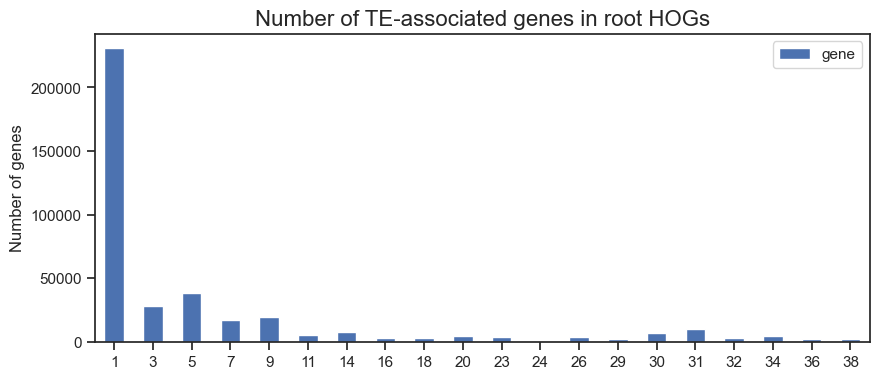

        gene
node        
1     230646
3      28411
5      38608
7      16904
9      19815
11      5226
14      7544
16      3317
18      2664
20      4896
23      3960
24       568
26      3584
29      2502
30      7053
31     10147
32      2864
34      4417
36      1844
38      2274
397244


In [186]:
### Get number per node plot

df = pd.read_csv(f'{rPath}te_node_unfiltered.tsv', sep='\t', usecols=[0,2], engine='python', on_bad_lines='skip')
# df.loc[df['node'].str.startswith('A'), 'node'] = 'Anc'
df = df.groupby('node').count()
df
main_nodes = [1, 3, 5, 7, 9, 11, 14, 16, 18, 20, 23, 24, 26, 29, 30, 31, 32, 34, 36, 38]
main_nodes = [str(x) for x in main_nodes]
df = df[df.index.isin(main_nodes)]
df.index = df.index.astype(int)
df = df.sort_index()

ax = df.plot(kind='bar', figsize=(10, 4))
plt.title('Number of TE-associated genes in root HOGs', fontsize=16)
plt.xlabel('')
plt.ylabel('Number of genes')
plt.xticks(rotation=360)

plt.savefig(f'{rPath}TEs_hogs_node.svg', bbox_inches='tight')
plt.show()
print(df)
print(df.sum().sum())

In [17]:
# 398861*100/460094
230646*100/460094

50.13019078710003

# TE verification

In [193]:
## Load the genes to hog info
te2hog = {}
for line in open(f'{rPath}te_node_unfiltered.tsv'):
    line = line.strip()
    data = line.split('\t')
    te2hog[data[0]] = data[1:]

In [195]:
## Load the new code names
tdf = pd.read_csv(taxaFile, sep='\t')
code2name = dict(zip(tdf.id, tdf.sciname))

In [200]:
Files = glob.glob(f'{rPath}te_fasta/*.cls.tsv')
te_names = ['DIRS','Helitron','LINE','LTR','mixture','pararetrovirus','TIR']
values = []
outfile = open(tes_confirmed,'w')
print('species\ttes\ttes_val\tpercentage', file=outfile)

outfile2 = open(f'{rPath}te_tesorter_analysis.tsv','w')
print('species\tisoforms\tmain_isoform\thog\tnode_tree\ttesorter_genes\tte_order\tte_superfamily', file=outfile2)

for file in Files:
    sp = file.split('/')[-1].split('.')[0]
    tes = load_te_type(file)
    data = [0]*len(te_names)
    tot, note = 0, 0
    for line in open(f'{rPath}te_fasta/{sp}.te.splice'):
        line = line.strip()
        genes = line.split(';')
        tot += 1
        common_genes = set(genes) & set(tes.keys())
        hog_genes = list(set(genes) & set(te2hog.keys()))
        if len(hog_genes)>0:
            hoginfo = f'{hog_genes[0][5:]}\t{'\t'.join(te2hog[hog_genes[0]])}'
        else:
            hoginfo = 'None\tNone\tNone'
        if len(common_genes) >0:
            te = set([tes[x][0] for x in common_genes])
            fam = set([tes[x][1] for x in common_genes])
            for name in te:
                key = te_names.index(name)
                data[key] += 1
            tesinfo = f'{';'.join([x[5:] for x in common_genes])}\t{';'.join(te)}\t{';'.join(fam)}'
        else:
            note += 1
            tesinfo = 'None\tNone\tNone'
        string = f'{code2name[genes[0][:5]]}\t{';'.join([x[5:] for x in genes])}\t{hoginfo}\t{tesinfo}'
        print(string,file=outfile2)
    data = [sp] + data
    values.append(data)
    print(sp, tot, tot - note, round((tot-note)*100/tot,2), sep='\t', file=outfile) 
outfile.close()
outfile2.close()

In [39]:
### save the dataframe of the types
df = pd.DataFrame(values, columns=['species'] + te_names)
df.to_csv(f'{rPath}te_types.tsv', sep='\t', index=False)

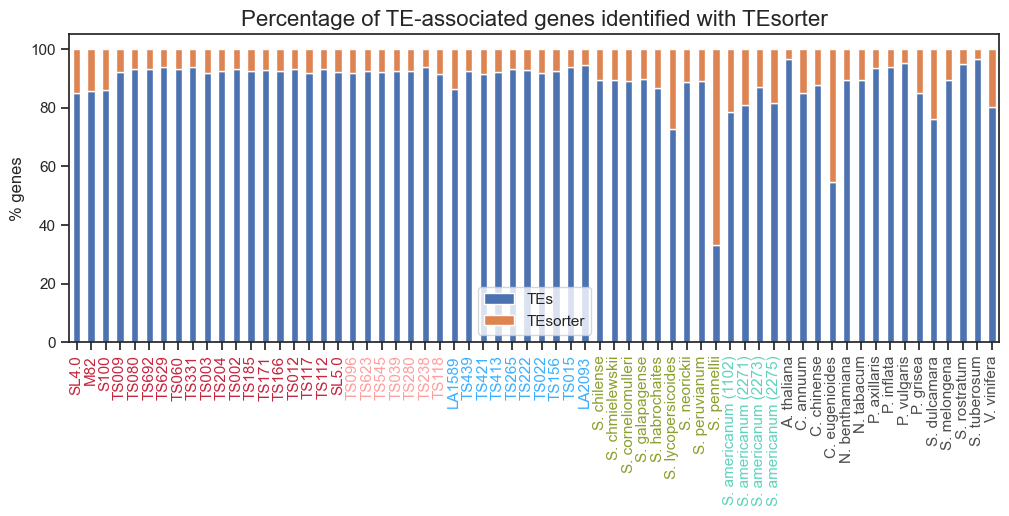

             TEs   TEsorter
count  64.000000  64.000000
mean   88.624590  11.375410
std     9.599988   9.599988
min    33.266337   3.417125
25%    87.595380   6.829387
50%    91.974420   8.025580
75%    93.170613  12.404620
max    96.582875  66.733663


In [38]:
### Plot about the precentage that is verified
nf = pd.read_csv(taxaFile, sep='\t')
id2names = dict(zip(nf.id, nf.sciname))

df = pd.read_csv(tes_confirmed, sep='\t', usecols=[0,1,2])
df.species = df.species.map(id2names)
df = df.set_index("species", drop=True)

df = df.astype(float)
df['TEs'] = df.tes - df.tes_val 
df.iloc[:, 2:] = df.iloc[:, 2:].div(df.iloc[:, 0], axis=0)*100
df = df[['TEs']]
df['TEsorter'] = 100 - df['TEs']
df = df.reindex(ordered_sp)

ax = df.plot(kind='bar', stacked=True, figsize=(12, 4))
plt.title('Percentage of TE-associated genes identified with TEsorter', fontsize=16)
plt.xlabel('')
plt.ylabel('% genes')
plt.xticks(rotation=90)
xticks = ax.get_xticklabels()

for i, label in enumerate(xticks):
    label.set_color(ordered_col[i % len(xticks)])  # Change colors

plt.savefig(f'{rPath}TE_validated_tesorter.svg', bbox_inches='tight')
plt.show()

print(df.describe())

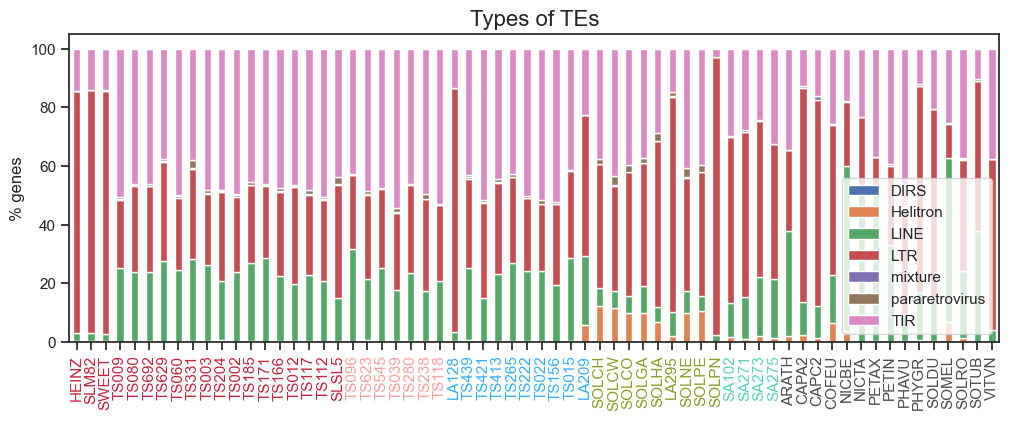

In [41]:
### make a plot
df = pd.read_csv(f'{rPath}te_types.tsv', sep='\t', index_col=0)
names = list(df.columns)
df['total'] = df.sum(axis=1)
## get percentages
for name in names:
    df[name] = df[name]*100/df['total']
df = df.drop(['total'], axis=1)
df = df.reindex(ordered_sp)

## plot
ax = df.plot(kind='bar', stacked=True, figsize=(12, 4))
plt.title('Types of TEs', fontsize=16)
plt.xlabel('')
plt.ylabel('% genes')
plt.xticks(rotation=90)
xticks = ax.get_xticklabels()

for i, label in enumerate(xticks):
    label.set_color(ordered_col[i % len(xticks)])  # Change colors

plt.savefig(f'{rPath}TE_tesorter_types.svg', bbox_inches='tight')
plt.show()

In [143]:
### get the name of the groups
df = pd.read_csv(taxaFile, sep='\t')
taxa2group = dict(zip(df['id'], df['taxa']))


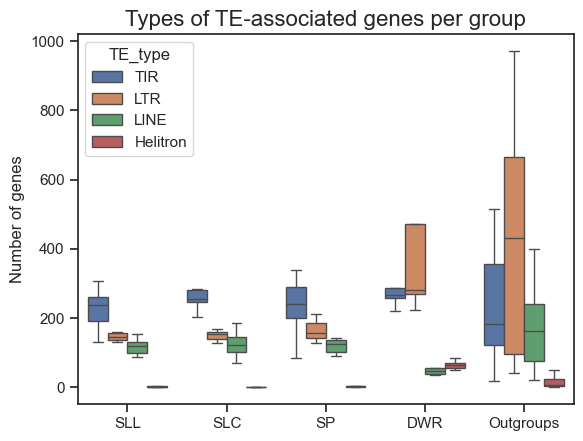

,group,TE_type,value
64,SP,Helitron,2
65,DWR,Helitron,58
66,DWR,Helitron,48
67,SP,Helitron,1
68,DWR,Helitron,56
...,...,...,...
443,SLC,TIR,255
444,SLC,TIR,249
445,Outgroups,TIR,160
446,Outgroups,TIR,18


In [146]:
### box plots
df = pd.read_csv(f'{rPath}te_types.tsv', sep='\t')
df['group'] = df['species'].map(taxa2group)
df = df.drop(['species'], axis=1)
df = df.melt(id_vars=['group'], var_name='TE_type', value_name='value')

te_names = ['TIR','LTR','LINE','Helitron']# 'DIRS',,,,'mixture','pararetrovirus',]
df = df[df.TE_type.isin(te_names)]
ax = sns.boxplot(data=df, x="group", y="value", hue="TE_type", order=['SLL','SLC','SP','DWR','Outgroups'], hue_order=te_names, showfliers=False)
plt.title('Types of TE-associated genes per group', fontsize=16)
plt.xlabel('')
plt.ylabel('Number of genes')
plt.savefig(f'{rPath}TE_tesorter_types_boxplot.svg', bbox_inches='tight')
plt.show()
# names = list(df.columns)
# df['total'] = df.sum(axis=1)
# ## get percentages
# for name in names:
#     df[name] = df[name]*100/df['total']

# df = df.reindex(ordered_sp)
df

In [39]:
groups = set(df.group.values)
groups = ['SLL','SLC', 'SP', 'DWR','Outgroups']
for group in groups:
    df2 = df[df.group == group]
    df2 = df2.drop('group',axis=1)
    df3 = df2.groupby('te_type').sum()
    df4 = df2.groupby('te_type').mean()
    tot = df3.sum().sum()
    df3['per'] = df3.value *100/tot
    df4['per'] = df4.value *100/tot
    print('######################################')
    print(group)
    print(df3)
    print(df4)

######################################
SLL
          value        per
te_type                   
Helitron     26   0.236364
LINE       2032  18.472727
LTR        4679  42.536364
TIR        4263  38.754545
               value       per
te_type                       
Helitron    1.368421  0.012440
LINE      106.947368  0.972249
LTR       246.263158  2.238756
TIR       224.368421  2.039713
######################################
SLC
          value        per
te_type                   
Helitron      9   0.238600
LINE        863  22.879109
LTR        1045  27.704136
TIR        1855  49.178155
               value       per
te_type                       
Helitron    1.285714  0.034086
LINE      123.285714  3.268444
LTR       149.285714  3.957734
TIR       265.000000  7.025451
######################################
SP
          value        per
te_type                   
Helitron     38   0.673878
LINE       1123  19.914879
LTR        2173  38.535201
TIR        2305  40.876042
          valu

In [42]:
### All species
highest_te = df.idxmax(axis=1)

counts = highest_te.value_counts()
print(counts)


TIR     35
LTR     24
LINE     5
Name: count, dtype: int64


In [43]:
## main groups

for color in order_colors:
    values = color_dic[color]
    df2 = df[df.index.isin(values)]
    highest_te = df2.idxmax(axis=1)
    counts = highest_te.value_counts()
    print(color)
    print(counts)
        

#C7253E
TIR    16
LTR     3
Name: count, dtype: int64
#FF9F9F
TIR    7
Name: count, dtype: int64
#3AB0FF
TIR    8
LTR    2
Name: count, dtype: int64
#89a02cff
LTR    7
TIR    2
Name: count, dtype: int64
#5fd3bcff
LTR    4
Name: count, dtype: int64
#4d4d4dff
LTR     8
LINE    5
TIR     2
Name: count, dtype: int64


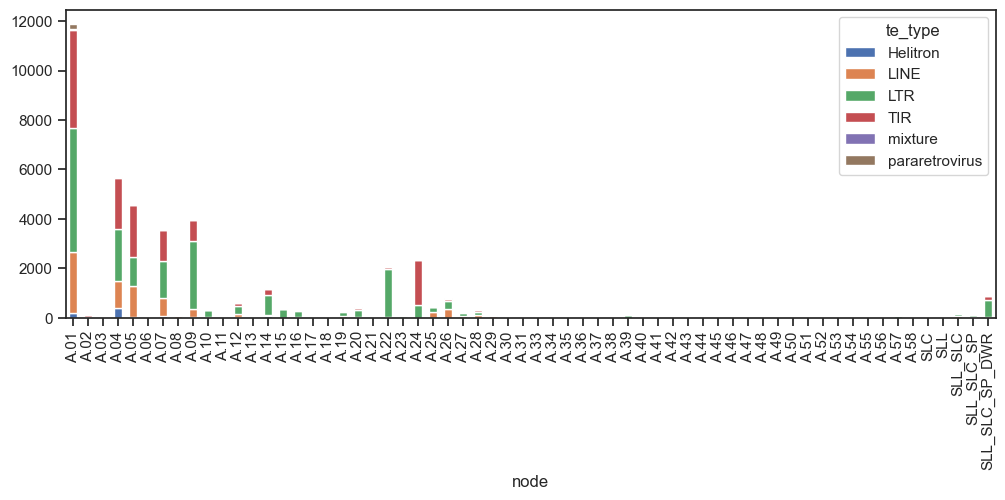

te_type         Helitron  LINE   LTR   TIR  mixture  pararetrovirus
node                                                               
A.01                 197  2478  5015  3952       34             199
A.02                   0     0     8    84        0               0
A.03                   0     0     5     0        0               0
A.04                 399  1068  2103  2096       18               3
A.05                  21  1249  1189  2088       23               3
...                  ...   ...   ...   ...      ...             ...
SLC                    0     3    15     7        0               0
SLL                    0    17     8     8        0               0
SLL_SLC                0    73    68    28        0               0
SLL_SLC_SP             0    34    62    12        0               0
SLL_SLC_SP_DWR        11    12   691   149        1               6

[62 rows x 6 columns]
%%%%%%%%%%%%%%%%%%%
te_type         Helitron      LINE        LTR       TIR   mixture  \
node

In [45]:
### Get number per node plot
df = pd.read_csv(f'{rPath}te_node_unfiltered_tesorter.tsv', sep='\t', usecols=[2,3])
# df.loc[df['node'].str.startswith('A'), 'node'] = 'Anc'
df = pd.crosstab(df['node'], df['te_type']).reset_index()
df = df.set_index('node')

ax = df.plot(kind='bar', stacked=True, figsize=(12, 4))
# plt.title('Number of TE-associated genes in root HOGs', fontsize=16)
# plt.xlabel('')
# plt.ylabel('number of genes')
# plt.xticks(rotation=90)
# xticks = ax.get_xticklabels()

# for i, label in enumerate(xticks):
#     label.set_color(ordered_col[i % len(xticks)])  # Change colors

plt.savefig(f'{rPath}TEs_tesorter_innodes.svg', bbox_inches='tight')
plt.show()
print(df)
print('%%%%%%%%%%%%%%%%%%%')
tot = df.sum().sum()
df_percentage = (df / tot) * 100
print(df_percentage)
print('%%%%%%%%%%%%%%%%%%%')
print(df.describe())
print(df.sum(axis=0))
print('############')
print(df.sum(axis=1))

